In [248]:
import pandas as pd
import numpy as np
from nltk.corpus import words,stopwords,wordnet,opinion_lexicon
import nltk
import re
import string
from transformers import AutoTokenizer
import spacy
from nltk.stem import PorterStemmer,WordNetLemmatizer
from pywaffle import Waffle
from wordcloud import WordCloud, STOPWORDS

nlp = spacy.load("en_core_web_sm")
nltk.download('words')
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('maxent_ne_chunker')
nltk.download('maxent_ne_chunker_tab')
nltk.download('words')
nltk.download('opinion_lexicon')

data = pd.read_csv('spooky.csv')

english_vocab = set(words.words())
stopwords = set(stopwords.words("english"))

[nltk_data] Downloading package words to
[nltk_data]     C:\Users\achou\AppData\Roaming\nltk_data...
[nltk_data]   Package words is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\achou\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\achou\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\achou\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package maxent_ne_chunker to
[nltk_data]     C:\Users\achou\AppData\Roaming\nltk_data...
[nltk_data]   Package maxent_ne_chunker is already up-to-date!
[nltk_data] Downloading package maxent_ne_chunker_tab to
[nltk_data]     C:\Users\acho

In [172]:
text = data['text'].values

def normalize_entities(text):

    text = re.sub(r'http\S+|www\.\S+', '<url>', text)
    
    text = re.sub(r'\S+@\S+', '<email>', text)
    
    return text

text_sentences =  [ nltk.sent_tokenize(i) for i in text ]

text_normalized_sentences =  [ [ normalize_entities(i) for i in sub ] for sub in text_sentences ]

text_word_tokenized = [ [nltk.word_tokenize(i) for i in sub] for sub in text_normalized_sentences ]

text_word_tokenized = [ [ [ i for i in sub if i not in string.punctuation and i not in stopwords and len(i) >= 3 ] for sub in sub2 ] for sub2 in text_word_tokenized ]

text_word_tokenized = [ [ [ i.lower() for i in sub] for sub in sub2] for sub2 in text_word_tokenized]

def semantic_normalize(word):
    
    pattern = re.compile(r'(.)\1{2,}')

    reduced_word = pattern.sub(r'\1\1', word)
    
    if english_vocab.__contains__(reduced_word):
        return reduced_word
    
    single_char_word = pattern.sub(r'\1', word)
    
    if english_vocab.__contains__(single_char_word):
        return single_char_word
        
    return reduced_word

In [174]:
homoglyph_map = {
    '$': 's',
    '0': 'o',
    '1': 'l',
    '3': 'e',
    '@': 'a',
    '!': 'i'
}

text_word_tokenized = [[[ ''.join([homoglyph_map.get(i, i) for i in word ]) for word in sub ] for sub in sub2 ] for sub2 in text_word_tokenized ]

In [176]:
text_subword = [ i for sub in text_normalized_sentences for i in sub ]

subword_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

subword_tokens = [ subword_tokenizer.tokenize(i) for i in text_subword ]

subword_tokens_no_puntuation = [ [ i for i in sub if i not in string.punctuation and i not in stopwords ] for sub in subword_tokens ]

Token indices sequence length is longer than the specified maximum sequence length for this model (953 > 512). Running this sequence through the model will result in indexing errors


In [177]:
subword_tokens_no_puntuation

[['process',
  'however',
  'afforded',
  'means',
  '##cer',
  '##tain',
  '##ing',
  'dimensions',
  'dungeon',
  'might',
  'make',
  'circuit',
  'return',
  'point',
  '##ce',
  'set',
  'without',
  'aware',
  'fact',
  'perfectly',
  'uniform',
  'seemed',
  'wall'],
 ['never', 'occurred', 'fu', '##mbling', 'might', 'mere', 'mistake'],
 ['left',
  'hand',
  'gold',
  '##nu',
  '##ff',
  'box',
  'cape',
  '##red',
  'hill',
  'cutting',
  'manner',
  'fantastic',
  'steps',
  'took',
  '##nu',
  '##ff',
  'inc',
  '##ess',
  '##antly',
  'air',
  'greatest',
  'possible',
  'self',
  'satisfaction'],
 ['lovely',
  'spring',
  'looked',
  'windsor',
  'terrace',
  'sixteen',
  'fertile',
  'counties',
  'spread',
  'beneath',
  'spec',
  '##kled',
  'happy',
  'cottages',
  'wealth',
  '##ier',
  'towns',
  'looked',
  'former',
  'years',
  'heart',
  'cheering',
  'fair'],
 ['finding',
  'nothing',
  'else',
  'even',
  'gold',
  'superintendent',
  'abandoned',
  'attempts',
 

In [178]:
tokens_pos_tagged = [ [ nltk.pos_tag(i) for i in sub] for sub in text_word_tokenized]

In [179]:
tokens_pos_tagged

[[[('this', 'DT'),
   ('process', 'NN'),
   ('however', 'RB'),
   ('afforded', 'VBD'),
   ('means', 'NNS'),
   ('ascertaining', 'VBG'),
   ('dimensions', 'NNS'),
   ('dungeon', 'NN'),
   ('might', 'MD'),
   ('make', 'VB'),
   ('circuit', 'NN'),
   ('return', 'NN'),
   ('point', 'NN'),
   ('whence', 'NN'),
   ('set', 'VBN'),
   ('without', 'IN'),
   ('aware', 'JJ'),
   ('fact', 'NN'),
   ('perfectly', 'RB'),
   ('uniform', 'JJ'),
   ('seemed', 'VBD'),
   ('wall', 'NN')]],
 [[('never', 'RB'),
   ('occurred', 'VBD'),
   ('fumbling', 'VBG'),
   ('might', 'MD'),
   ('mere', 'VB'),
   ('mistake', 'VB')]],
 [[('left', 'JJ'),
   ('hand', 'NN'),
   ('gold', 'NN'),
   ('snuff', 'NN'),
   ('box', 'NN'),
   ('capered', 'VBD'),
   ('hill', 'JJ'),
   ('cutting', 'VBG'),
   ('manner', 'NN'),
   ('fantastic', 'JJ'),
   ('steps', 'NNS'),
   ('took', 'VBD'),
   ('snuff', 'NN'),
   ('incessantly', 'RB'),
   ('air', 'VBZ'),
   ('greatest', 'JJS'),
   ('possible', 'JJ'),
   ('self', 'NN'),
   ('satisfactio

In [180]:
ner_sentences = [ [ nlp(i) for i in sub ] for sub in text_normalized_sentences ]

In [187]:
spacy.displacy.render(ner_sentences[17000][0], style="ent", jupyter=True)

In [199]:
entities_by_sentence = []

for i in range(len(ner_sentences)):
    entities = []
    for j in range(len(ner_sentences[i])):
        for ent in ner_sentences[i][j].ents:
            if ent.label_ in ["PERSON","ORG","GPE","DATE"]:
             entities.append((ent.text, ent.label_))      
    entities_by_sentence.append(entities)

In [204]:
frequencies_by_author = dict()
frequencies = dict()    
    
for i in range(len(entities_by_sentence)):
    for entity in entities_by_sentence[i]:
        if entity[1] in frequencies:
          frequencies[entity[1]] += 1
        else:
          frequencies[entity[1]] = 1
        if data.iloc[i]['author'] in frequencies_by_author:
          if entity[1] in frequencies_by_author[data.iloc[i]['author']]:
            frequencies_by_author[data.iloc[i]['author']][entity[1]] += 1
          else:
            frequencies_by_author[data.iloc[i]['author']][entity[1]] = 1
        else:
          frequencies_by_author[data.iloc[i]['author']] = dict()
          frequencies_by_author[data.iloc[i]['author']][entity[1]] = 1
            
print(frequencies)
print(frequencies_by_author)

{'ORG': 2113, 'DATE': 1735, 'PERSON': 3735, 'GPE': 1714}
{'MWS': {'ORG': 475, 'DATE': 608, 'GPE': 679, 'PERSON': 991}, 'HPL': {'PERSON': 1469, 'ORG': 810, 'GPE': 567, 'DATE': 579}, 'EAP': {'PERSON': 1275, 'GPE': 468, 'ORG': 828, 'DATE': 548}}


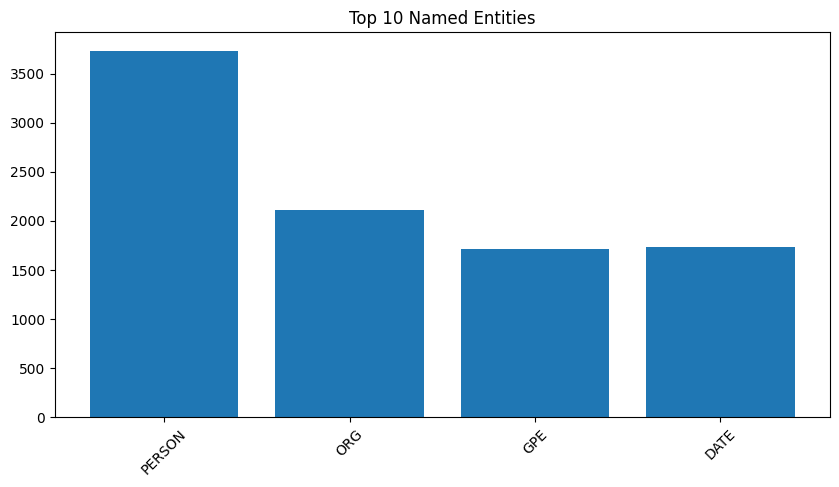

In [205]:
import matplotlib.pyplot as plt

names = ["PERSON","ORG","GPE","DATE"]
counts = [ frequencies["PERSON"] , frequencies["ORG"] , frequencies["GPE"] , frequencies["DATE"] ]

plt.figure(figsize=(10,5))
plt.bar(names, counts)
plt.xticks(rotation=45)
plt.title("Top 10 Named Entities")
plt.show()

In [222]:
myStemmer = PorterStemmer()

sample_sentence = text_normalized_sentences[10000][0]
tokenized = nltk.word_tokenize(sample_sentence)
tokenized
stemmed = [ myStemmer.stem(word=token) for token in tokenized ]
stemmed

['frequent',
 'he',
 'would',
 'glanc',
 'at',
 'the',
 'door',
 'as',
 'if',
 'he',
 'expect',
 'someon',
 ',',
 'and',
 'at',
 'length',
 'hi',
 'glanc',
 'seem',
 'answer',
 'by',
 'a',
 'singular',
 'rap',
 'which',
 'must',
 'have',
 'follow',
 'some',
 'veri',
 'ancient',
 'and',
 'secret',
 'code',
 '.']

In [223]:
myLemmetizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

pos_tagged_tokens = nltk.pos_tag(tokenized)

lemmas = [myLemmetizer.lemmatize(tok, get_wordnet_pos(pos)) 
              for tok, pos in pos_tagged_tokens if tok.isalpha()]

lemmas

['Frequently',
 'he',
 'would',
 'glance',
 'at',
 'the',
 'door',
 'a',
 'if',
 'he',
 'expect',
 'someone',
 'and',
 'at',
 'length',
 'his',
 'glance',
 'seem',
 'answer',
 'by',
 'a',
 'singular',
 'rap',
 'which',
 'must',
 'have',
 'follow',
 'some',
 'very',
 'ancient',
 'and',
 'secret',
 'code']

In [224]:
doc = nlp(sample_sentence)
lemmas = [token.lemma_ for token in doc if token.is_alpha]
lemmas

['frequently',
 'he',
 'would',
 'glance',
 'at',
 'the',
 'door',
 'as',
 'if',
 'he',
 'expect',
 'someone',
 'and',
 'at',
 'length',
 'his',
 'glance',
 'seemed',
 'answer',
 'by',
 'a',
 'singular',
 'rapping',
 'which',
 'must',
 'have',
 'follow',
 'some',
 'very',
 'ancient',
 'and',
 'secret',
 'code']

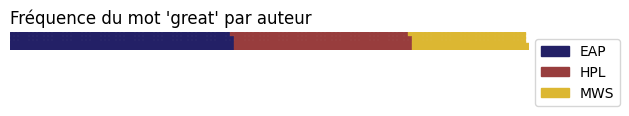

In [250]:
def plot_waffle(word, df):

    mask = df['text'].str.contains(word, case=False, na=False)
    
    counts = df[mask].groupby('author').size()

    data_waffle = counts.to_dict()

    if not data_waffle:
        print(f"Le mot '{word}' n'a pas été trouvé.")
        return

    plt.figure(
        FigureClass=Waffle,
        rows=5,
        values=data_waffle,
        colors=["#232066", "#983D3D", "#DCB732"],
        title={'label': f"Fréquence du mot '{word}' par auteur", 'loc': 'left'},
        legend={'loc': 'upper left', 'bbox_to_anchor': (1, 1)}
    )
    plt.show()

plot_waffle("great",data)

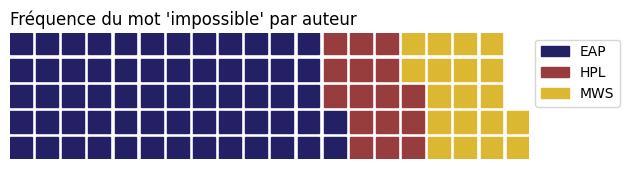

In [251]:
plot_waffle("impossible",data)

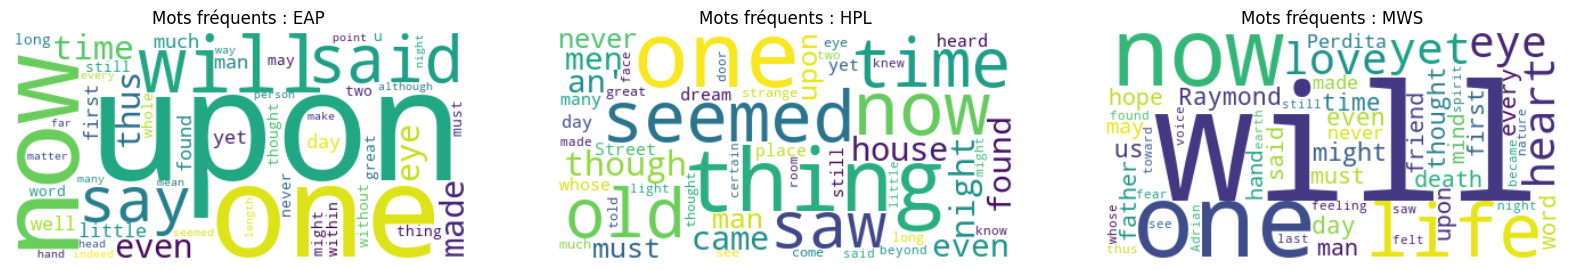

In [246]:
auteurs = data['author'].unique()

stopwords = set(STOPWORDS) 

plt.figure(figsize=(20, 5))

for i, auteur in enumerate(auteurs):

    text_auteur = " ".join(data[data['author'] == auteur]['text'].astype(str))
    
    wc = WordCloud(background_color="white", stopwords=stopwords, max_words=50).generate(text_auteur)
    
    plt.subplot(1, 3, i+1) 
    plt.imshow(wc, interpolation='bilinear')
    plt.axis("off")
    plt.title(f"Mots fréquents : {auteur}")

plt.show()

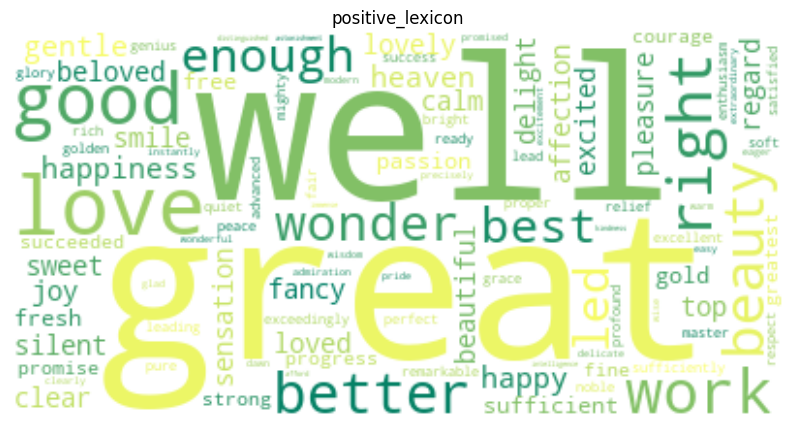

In [252]:
positive_lexicon = set(opinion_lexicon.positive())
negative_lexicon = set(opinion_lexicon.negative())

tokens = [ i for sub1 in text_word_tokenized for sub2 in sub1 for i in sub2 ]

positive_words_found = [word for word in tokens if word in positive_lexicon]
negative_words_found = [word for word in tokens if word in negative_lexicon]

text_string = " ".join(positive_words_found)
    
wc = WordCloud(background_color="white", max_words=100, colormap="summer").generate(text_string)
    
plt.figure(figsize=(10, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")
plt.title("positive_lexicon")
plt.show()



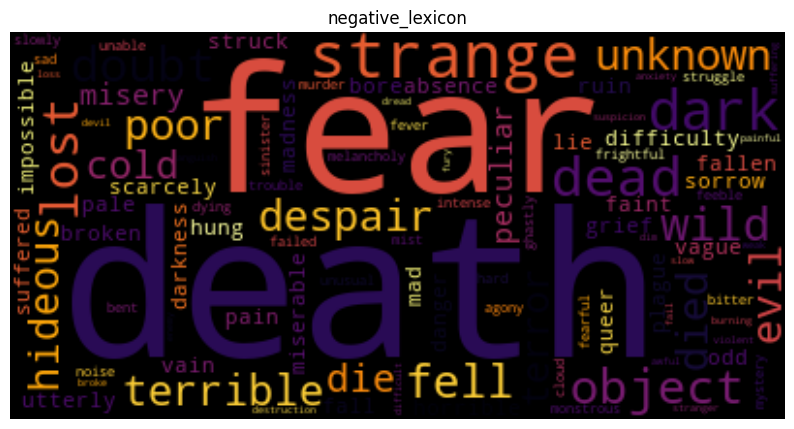

In [254]:
text_string = " ".join(negative_words_found)
    
wc = WordCloud(background_color="black", max_words=100, colormap="inferno").generate(text_string)
    
plt.figure(figsize=(10, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")
plt.title("negative_lexicon")
plt.show()